# FUTURE_ML_01 — Sales & Demand Forecasting
**Intern:** Saurabh Kumar Singh  
**Track:** Machine Learning | **Task:** 1  
**Organization:** Future Interns

## Objective
Build a practical sales forecasting workflow from historical business data, evaluate it using a chronological holdout, and present business-friendly visualizations. This notebook uses the Superstore sales dataset and aggregates transaction-level sales into a monthly time series.

**Dataset:** `Sample - Superstore.csv.zip`  
**Date column:** `Order Date`  
**Target column:** `Sales`  
**Forecast horizon:** 3 months (January–March 2018)

The notebook has been executed on the dataset. Reported metrics and forecast values are based on the saved execution outputs.

## 1. Install and import libraries

In [28]:
!pip -q install pandas numpy matplotlib scikit-learn

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from google.colab import files
import io, math, warnings
warnings.filterwarnings('ignore')
plt.rcParams['figure.figsize'] = (12, 5)

## 2. Upload and inspect the dataset
The ZIP dataset is read from `/content/Sample - Superstore.csv.zip`, which must already be present in the current Colab runtime. The cell extracts the CSV in memory and reads it using `latin1` encoding.

In [29]:
import pandas as pd
import zipfile
from IPython.display import display

# Connect to already uploaded dataset
file_path = "/content/Sample - Superstore.csv.zip"

# Extract and read CSV
with zipfile.ZipFile(file_path, "r") as z:
    csv_files = [f for f in z.namelist() if f.endswith(".csv")]

    print("CSV files:", csv_files)

    with z.open(csv_files[0]) as file:
        df = pd.read_csv(file, encoding="latin1")

# Inspect dataset
print("Dataset Shape:", df.shape)

print("\nFirst 5 Rows:")
display(df.head())

print("\nColumns:")
print(df.columns.tolist())

print("\nMissing Values:")
display(df.isnull().sum().sort_values(ascending=False).head(15))

CSV files: ['Sample - Superstore.csv']
Dataset Shape: (9994, 21)

First 5 Rows:


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164



Columns:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']

Missing Values:


,0
Row ID,0
Order ID,0
Order Date,0
Ship Date,0
Ship Mode,0
Customer ID,0
Customer Name,0
Segment,0
Country,0
City,0


## 3. Select columns and clean data
Set `DATE_COL` and `SALES_COL` to the exact column names printed above. For the Superstore dataset, common names are `Order Date` and `Sales`.

In [30]:
DATE_COL = 'Order Date'  # change if your dataset uses another name
SALES_COL = 'Sales'      # change if your dataset uses another name
FREQUENCY = 'MS'          # 'D' daily or 'MS' monthly; use monthly for sparse/irregular data
FORECAST_PERIODS = 3

assert DATE_COL in df.columns, f'{DATE_COL} not found. Available: {df.columns.tolist()}'
assert SALES_COL in df.columns, f'{SALES_COL} not found. Available: {df.columns.tolist()}'

data = df[[DATE_COL, SALES_COL]].copy()
data[DATE_COL] = pd.to_datetime(data[DATE_COL], errors='coerce')
data[SALES_COL] = pd.to_numeric(data[SALES_COL], errors='coerce')
data = data.dropna(subset=[DATE_COL, SALES_COL])
data = data[data[SALES_COL] >= 0]
data = data.sort_values(DATE_COL)

# Aggregate transaction-level records into a regular time series
ts = (data.set_index(DATE_COL)[SALES_COL]
       .resample(FREQUENCY).sum()
       .asfreq(FREQUENCY, fill_value=0)
       .rename('sales').to_frame())
print('Clean time-series shape:', ts.shape)
print('Date range:', ts.index.min(), 'to', ts.index.max())
display(ts.head())
display(ts.describe())

Clean time-series shape: (48, 1)
Date range: 2014-01-01 00:00:00 to 2017-12-01 00:00:00


,sales
Order Date,
2014-01-01,14236.895
2014-02-01,4519.892
2014-03-01,55691.009
2014-04-01,28295.345
2014-05-01,23648.287


,sales
count,48.000000
mean,47858.351256
std,25195.890700
min,4519.892000
25%,29790.096125
50%,39803.248500
75%,65833.343625
max,118447.825000


## 4. Explore sales trends and seasonality

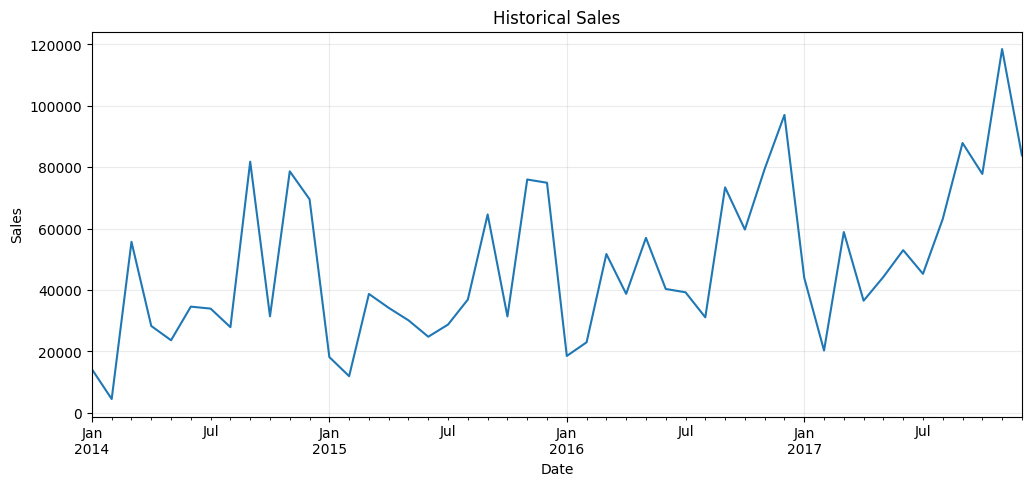

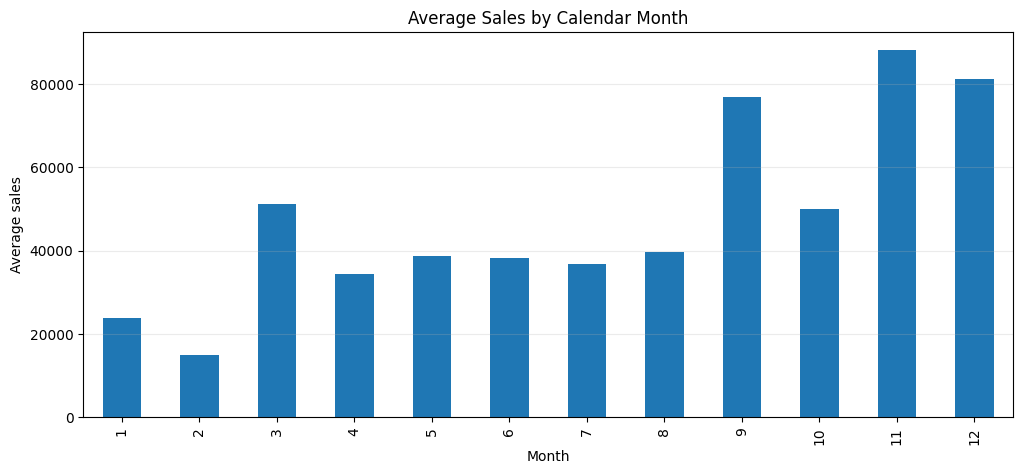

Missing values in aggregated series: 0
Zero-sales periods: 0


In [31]:
ts['sales'].plot(title='Historical Sales')
plt.xlabel('Date'); plt.ylabel('Sales'); plt.grid(alpha=.25); plt.show()

# Month-of-year pattern (useful for both daily and monthly data)
monthly_pattern = ts.groupby(ts.index.month)['sales'].mean()
monthly_pattern.plot(kind='bar', title='Average Sales by Calendar Month')
plt.xlabel('Month'); plt.ylabel('Average sales'); plt.grid(axis='y', alpha=.25); plt.show()

print('Missing values in aggregated series:', ts['sales'].isna().sum())
print('Zero-sales periods:', (ts['sales'] == 0).sum())

## 5. Create time-based features and a chronological split
The final 20% of eligible periods are kept for testing. The model is trained only on earlier observations to avoid time leakage. Test predictions are evaluated one month at a time using the previous observed month's sales as lag information; this is a one-step-ahead holdout evaluation. The separate future forecast in Section 8 is recursive.

In [32]:
def make_features(series):
    x = pd.DataFrame(index=series.index)
    x['trend'] = np.arange(len(series))
    x['month'] = series.index.month
    x['quarter'] = series.index.quarter
    x['dayofweek'] = series.index.dayofweek
    x['dayofyear'] = series.index.dayofyear
    x['lag_1'] = series.shift(1)
    x['lag_2'] = series.shift(2)
    x['lag_3'] = series.shift(3)
    x['lag_7'] = series.shift(7)
    x['rolling_mean_7'] = series.shift(1).rolling(7).mean()
    return x

X_all = make_features(ts['sales'])
model_data = X_all.join(ts['sales'].rename('target')).dropna()
if len(model_data) < 20:
    raise ValueError('Not enough time periods after feature creation. Choose monthly/daily frequency appropriately or use a longer dataset.')
split = int(len(model_data) * 0.8)
train, test = model_data.iloc[:split], model_data.iloc[split:]
X_train, y_train = train.drop(columns='target'), train['target']
X_test, y_test = test.drop(columns='target'), test['target']
print('Training periods:', len(train), '| Testing periods:', len(test))
print('Train end:', train.index.max(), '| Test start:', test.index.min())

Training periods: 32 | Testing periods: 9
Train end: 2017-03-01 00:00:00 | Test start: 2017-04-01 00:00:00


## 6. Train a baseline and a machine-learning model

In [33]:
# Baseline: predict each period using the previous period's sales
baseline_pred = X_test['lag_1'].values

model = RandomForestRegressor(n_estimators=300, random_state=42, min_samples_leaf=2)
model.fit(X_train, y_train)
model_pred = model.predict(X_test)

def metrics(actual, predicted, name):
    mae = mean_absolute_error(actual, predicted)
    rmse = mean_squared_error(actual, predicted) ** 0.5
    nonzero = np.asarray(actual) != 0
    mape = (np.abs((np.asarray(actual)[nonzero] - np.asarray(predicted)[nonzero]) / np.asarray(actual)[nonzero]).mean() * 100) if nonzero.any() else np.nan
    return {'Model': name, 'MAE': mae, 'RMSE': rmse, 'MAPE_percent_nonzero': mape}

results = pd.DataFrame([metrics(y_test, baseline_pred, 'Previous-period baseline'),
                        metrics(y_test, model_pred, 'Random Forest')])
display(results.round(2))

,Model,MAE,RMSE,MAPE_percent_nonzero
0,Previous-period baseline,19389.97,22560.14,28.58
1,Random Forest,14971.53,19285.92,19.63


## 7. Compare actual and predicted sales

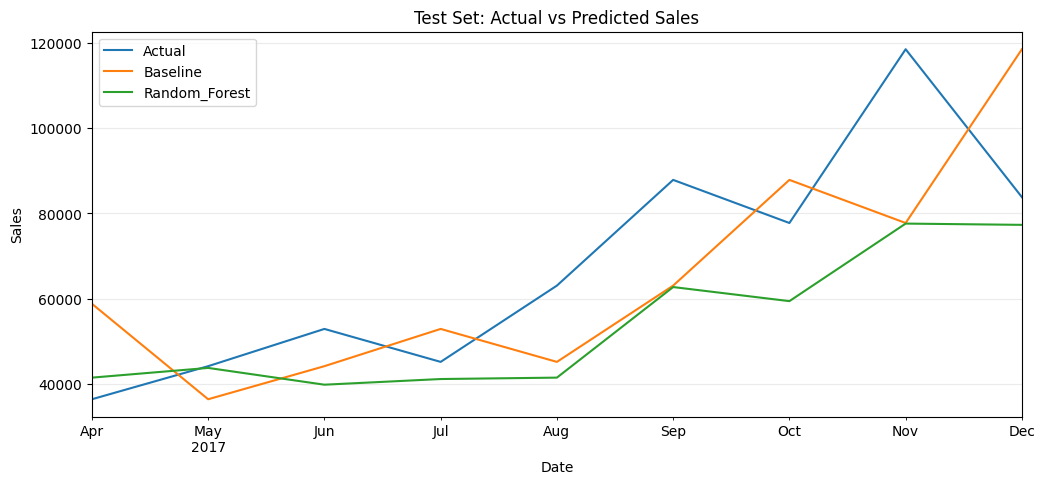

,Actual,Baseline,Random_Forest
Order Date,,,
2017-04-01,36521.54,58872.35,41579.58
2017-05-01,44261.11,36521.54,43854.53
2017-06-01,52981.73,44261.11,39926.47
2017-07-01,45264.42,52981.73,41252.40
2017-08-01,63120.89,45264.42,41581.62
2017-09-01,87866.65,63120.89,62782.39
2017-10-01,77776.92,87866.65,59486.17
2017-11-01,118447.82,77776.92,77638.16
2017-12-01,83829.32,118447.82,77341.38


In [34]:
comparison = pd.DataFrame({'Actual': y_test, 'Baseline': baseline_pred, 'Random_Forest': model_pred}, index=y_test.index)
comparison.plot(title='Test Set: Actual vs Predicted Sales')
plt.xlabel('Date'); plt.ylabel('Sales'); plt.grid(alpha=.25); plt.show()
display(comparison.head(15).round(2))

## 8. Forecast future periods

,Forecast_Sales
2018-01-01,32529.55
2018-02-01,34520.21
2018-03-01,42679.41


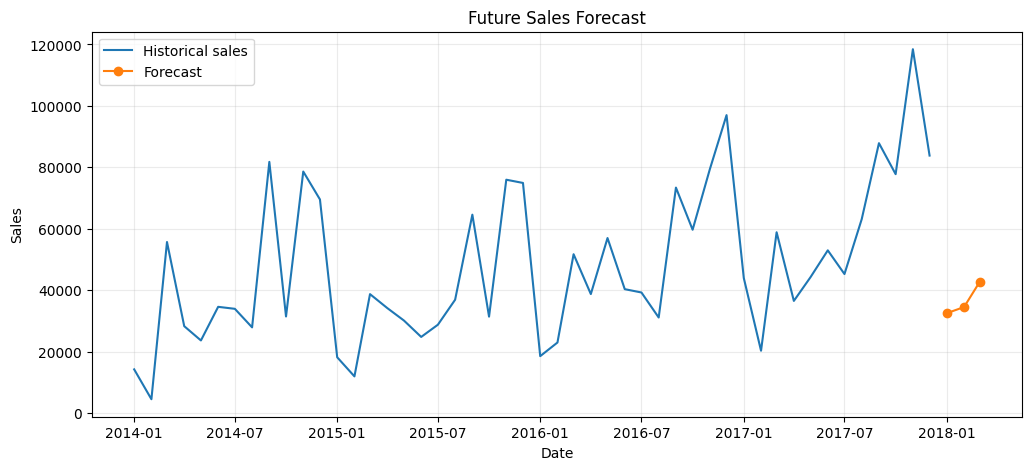

In [35]:
# Recursive multi-step forecast: each prediction is fed into the next time step
history = ts['sales'].copy()
future_dates = pd.date_range(start=history.index[-1] + pd.tseries.frequencies.to_offset(FREQUENCY),
                             periods=FORECAST_PERIODS, freq=FREQUENCY)
future_values = []
for date in future_dates:
    feats = make_features(history).iloc[[-1]].copy()
    # Construct the feature row for the new date using available history
    vals = {
        'trend': len(history), 'month': date.month, 'quarter': date.quarter,
        'dayofweek': date.dayofweek, 'dayofyear': date.dayofyear,
        'lag_1': history.iloc[-1], 'lag_2': history.iloc[-2], 'lag_3': history.iloc[-3],
        'lag_7': history.iloc[-7] if len(history) >= 7 else history.mean(),
        'rolling_mean_7': history.tail(7).mean()
    }
    pred = max(0, float(model.predict(pd.DataFrame([vals]))[0]))
    future_values.append(pred)
    history.loc[date] = pred
forecast = pd.DataFrame({'Forecast_Sales': future_values}, index=future_dates)
display(forecast.round(2))

plt.plot(ts.index, ts['sales'], label='Historical sales')
plt.plot(forecast.index, forecast['Forecast_Sales'], marker='o', label='Forecast')
plt.title('Future Sales Forecast'); plt.xlabel('Date'); plt.ylabel('Sales')
plt.legend(); plt.grid(alpha=.25); plt.show()

## 9. Business interpretation

### Findings from the executed dataset
1. The dataset contains **9,994 transaction records** and **21 columns**. The selected monthly time series contains **48 periods**, from January 2014 through December 2017.
2. No missing values were reported in the inspected dataset columns. The aggregated monthly sales series also contains no missing or zero-sales periods.
3. The Random Forest model performed better than the previous-period baseline on the chronological test set across all three reported metrics: MAE **14,971.53** vs **19,389.97**, RMSE **19,285.92** vs **22,560.14**, and MAPE **19.63%** vs **28.58%**.
4. The test period covers April–December 2017. The model underestimated the large November 2017 sales peak: actual sales were **118,447.82**, while the Random Forest prediction was **77,638.16**.
5. The recursive forecast estimates sales of **32,529.55** for January 2018, **34,520.21** for February 2018, and **42,679.41** for March 2018.

### Business applications
- Use the forecast as one input for inventory and replenishment planning.
- Use historical trends to support sales, staffing, and resource planning.
- Review forecast estimates alongside current market conditions and operational knowledge.

### Limitations
- Promotions, holidays, price changes, stockouts, and market events are not explicitly included as model features.
- The monthly history contains 48 observations, which limits the amount of data available for model learning.
- The Random Forest model did not capture the November 2017 sales spike accurately.
- The future forecast is recursive, so an earlier forecast error can affect later forecast periods.
- MAPE is calculated only for test observations with non-zero actual sales.
- These forecasts are estimates, not guaranteed future sales.

## 10. Export forecast and evaluation results

In [36]:
forecast.to_csv('future_sales_forecast.csv')
results.to_csv('model_evaluation.csv', index=False)
comparison.to_csv('test_predictions.csv')
print('Saved: future_sales_forecast.csv, model_evaluation.csv, test_predictions.csv')
files.download('future_sales_forecast.csv')
files.download('model_evaluation.csv')
files.download('test_predictions.csv')

Saved: future_sales_forecast.csv, model_evaluation.csv, test_predictions.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Submission checklist
- [x] Run the notebook on the Superstore dataset.
- [x] Verify date and sales column names.
- [x] Review data cleaning and monthly time-series aggregation.
- [x] Record actual MAE/RMSE/MAPE results.
- [x] Add business insights and limitations based on executed outputs.
- [x] Generate forecast, evaluation, and test-prediction CSV files.
- [ ] Save the final notebook and graph screenshots to the project folder.
- [ ] Publish in a **public** GitHub repository named `FUTURE_ML_01`.
- [ ] Submit through the official Future Interns portal using the CIN from the offer letter.